# How-to CleanCloud CHOPIN data
This notebook shows a step-by-step example of how to read the various available files, how to inspect metadata, and how to make basic plots.

Contents:
- Data location & file naming
- Cloudnet L1 data (.nc)
  - Loading and plotting vertically pointing data for all radars as well as for the different BASTA modes (2025-01-15 and 2024-12-05)
  - Loading and plotting scans for MXPol and MIRA (2024-12-05)
- Zenodo data (.zarr)
  - Loading and plotting vertically pointing data for all radars (2025-01-15 and 2024-12-05)

In [1]:
# imports
import sys, os, glob, pyart

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt 
import matplotlib.dates as mdates

from matplotlib.ticker import FuncFormatter

In [2]:
plt.rcParams.update({
    'axes.titlesize': 16,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'figure.titlesize': 16,
})

In [3]:
# metek variable/attribute maps for pyart
metek_fieldmapping = {
    'Zg': 'reflectivity',
    'Zcx': 'reflectivity_cx',
    'VELg': 'velocity',
    'RMSg': 'spectrum_width',
    'SNRg': 'signal_to_noise_ratio',
    'SNRcx': 'signal_to_noise_ratio_cx',
    'LDRg': 'linear_depolarization_ratio',
    'RHO': 'cross_correlation_ratio',
    'RHO_wav': 'cross_correlation_ratio_wav',
    'DPS': 'differential_phase',
    'SKWg': 'skewness',
    'NPKg': 'number_of_peaks',
    'SNRCorFaCo': 'snr_correction_factor_co',
    'SNRCorFaCx': 'snr_correction_factor_cx',
}

metek_fieldmetadata = {
    'reflectivity': {
        'units': 'dBZ',
        'long_name': 'Equivalent reflectivity factor',
        'standard_name': 'equivalent_reflectivity_factor',
        'valid_min': -80.0,
        'valid_max': 80.0,
    },
    'velocity': {
        'units': 'm/s', 
        'long_name': 'Mean Doppler velocity',
        'standard_name': 'radial_velocity_of_scatterers_away_from_instrument',
        'valid_min': -50.0,
        'valid_max': 50.0,
    },
    'spectrum_width': {
        'units': 'm/s',
        'long_name': 'Doppler spectrum width', 
        'standard_name': 'doppler_spectrum_width',
        'valid_min': 0.0,
        'valid_max': 20.0,
    },
    'signal_to_noise_ratio': {
        'units': 'dB',
        'long_name': 'Signal-to-noise ratio',
        'valid_min': -20.0,
        'valid_max': 80.0,
    },
    'linear_depolarization_ratio': {
        'units': 'dB',
        'long_name': 'Linear depolarization ratio',
        'valid_min': -40.0,
        'valid_max': 0.0,
    },
    'cross_correlation_ratio': {
        'units': '',
        'long_name': 'Cross-correlation coefficient',
        'valid_min': 0.0,
        'valid_max': 1.0,
    },
    'differential_phase': {
        'units': 'degrees',
        'long_name': 'Differential phase shift',
    },
    'skewness': {
        'units': '',
        'long_name': 'Doppler spectrum skewness',
    },
}

metek_attrmapping = {
    # Institution/source info
    'institution': 'institution',
    'source': 'source', 
    'references': 'references',
    'comment': 'comment',
    'history': 'history',
    
    # Instrument info
    'instrument_name': 'instrument_name',
    'instrument_type': 'instrument_type',
    'platform_type': 'platform_type',
    'primary_axis': 'primary_axis',
    'data_level': 'data_level',
    'scan_type': 'scan_type',
    'scan_name': 'scan_name',
    
    # Location - Metek specific names
    'Latitude': 'latitude',
    'lat': 'latitude', 
    'Longitude': 'longitude',
    'lon': 'longitude',
    'Altitude': 'altitude',
    'alt': 'altitude',
    'height': 'altitude',
    
    # Time info
    'time_coverage_start': 'time_coverage_start',
    'time_coverage_end': 'time_coverage_end',
    'time_reference': 'time_reference',
    
    # Radar parameters
    'frequency': 'frequency',
    'wavelength': 'wavelength', 
    'pulse_width': 'pulse_width',
    'prt': 'prt',
    'prt_mode': 'prt_mode',
    'nyquist_velocity': 'nyquist_velocity',
    'unambiguous_range': 'unambiguous_range',
    'beamwidth_h': 'radar_beam_width_h',
    'beamwidth_v': 'radar_beam_width_v',
    'antenna_gain': 'radar_antenna_gain',
    
    # Processing info
    'signal_processor': 'signal_processor',
    'calibration_constant': 'radar_constant',
    'receiver_gain': 'receiver_gain',
    'noise_floor': 'noise_floor',
    'range_resolution': 'range_resolution',
    'gate_spacing': 'range_resolution',
    
    # Quality control
    'qc_procedure': 'qc_procedure',
    'qc_comment': 'qc_comment',
    
    # Metek specific
    'software_version': 'signal_processor_version',
    'config_file': 'instrument_parameters',
    'measurement_type': 'scan_type',
}
# coordinate mappings
metek_coordattrs = {
    'time': {
        'standard_name': 'time',
        'long_name': 'Time in seconds since volume start',
        'units': 'seconds since start_time',
        'calendar': 'gregorian',
    },
    'range': {
        'standard_name': 'projection_range_coordinate', 
        'long_name': 'Range to center of gate',
        'units': 'm',
        'spacing_is_constant': 'true',
        'meters_to_center_of_first_gate': 'first_gate_distance',
        'meters_between_gates': 'gate_spacing',
    },
    'azimuth': {
        'standard_name': 'ray_azimuth_angle',
        'long_name': 'Azimuth angle from true north',
        'units': 'degrees',
        'positive': 'clockwise_from_north',
    },
    'elevation': {
        'standard_name': 'ray_elevation_angle', 
        'long_name': 'Elevation angle from horizontal plane',
        'units': 'degrees',
        'positive': 'up',
    },
    'latitude': {
        'standard_name': 'latitude',
        'long_name': 'Latitude of radar',
        'units': 'degrees_north',
    },
    'longitude': {
        'standard_name': 'longitude',
        'long_name': 'Longitude of radar', 
        'units': 'degrees_east',
    },
    'altitude': {
        'standard_name': 'altitude',
        'long_name': 'Altitude of radar above mean sea level',
        'units': 'm',
        'positive': 'up',
    }
}

In [4]:
# helper functions
def meters_to_km(y, _):
    """plotting helper"""
    return f"{y / 1000:.1f} km"


def regrid_time(da, t0, t1, freq):
    """helper function to regularise time axis (when using xr.open_mfdataset only available timesteps are """
    t_reg = pd.date_range(t0, t1, freq=freq)
    tol = pd.Timedelta(freq) / 2
    da = da.sortby('time').drop_duplicates('time', keep='first')
    return da.reindex(time=t_reg, method='nearest', tolerance=tol)
    

def get_clean_mask(data: xr.DataArray, min_points_range=3, min_time=30) -> np.ndarray:
    """noise mask (0 = noise/invalid, 1 = valid data) with the same shape as 'data' (binary dilation)
    
    data : xr.DataArray of input reflectivity/power, shape (time, range)
    min_points_range : int, min. distance between consecutive valid range gates [m]
    min_time : int, min. time between consecutive valid time steps [s]"""
    isval = data.notnull().values
    
    # time step in seconds ds.t
    if not (type(data.time.values[0]) == int or type(data.time.values[0]) == np.int32):
        dt = int((data.time.values[1] - data.time.values[0])/1e9)
        min_points_time = int(np.round(min_time / dt))
    else:
        min_points_time = min_time
    
    # valid ranges
    consecutive_range_check = np.zeros_like(isval, dtype=bool)
    
    # (manually shifting the data, check if the window contains enough consecutive valid points)
    for offset in range(-min_points_range + 1, min_points_range):
        shifted = np.zeros_like(isval)
        
        if offset < 0:
            shifted[:, :offset] = isval[:, -offset:]
        elif offset > 0:
            shifted[:, offset:] = isval[:, :-offset]
        else:  # offset == 0
            shifted = isval.copy()
            
        if offset == -min_points_range + 1:
            window = shifted
        else:
            window = window & shifted
            
        if (offset - (-min_points_range + 1) + 1) >= min_points_range:
            valid = window
            consecutive_range_check = consecutive_range_check | valid
            if offset < min_points_range - 1:
                window = shifted
    
    # valid times
    consecutive_time_check = np.zeros_like(isval, dtype=bool)
    
    # binary dilation for time dimension
    for offset in range(-min_points_time + 1, min_points_time):
        # Create shifted arrays
        shifted = np.zeros_like(isval)
        
        if offset < 0:
            shifted[:offset, :] = isval[-offset:, :]
        elif offset > 0:
            shifted[offset:, :] = isval[:-offset, :]
        else:  # offset == 0
            shifted = isval.copy()
            
        if offset == -min_points_time + 1:
            window = shifted
        else:
            window = window & shifted
            
        if (offset - (-min_points_time + 1) + 1) >= min_points_time:
            valid = window
            consecutive_time_check = consecutive_time_check | valid
            if offset < min_points_time - 1:
                window = shifted
    
    clean_mask = isval & (~consecutive_range_check | ~consecutive_time_check)
    
    return ~clean_mask

    
def preprocess_MIRA(ds, variable='Z', lin_to_dB=True, noise_method='hildebrandsekhon', stdev_threshold=2, n_fft=1, block_size=200):
    """filter/preprocess MIRA-data to remove noise & background mask & convert variabels to dB"""
    mask = get_clean_mask(ds[variable])
    mask_xr = ds[variable].copy(data=mask)
    ds = ds.assign(clean_mask=mask_xr)
    
    for var in ds.data_vars: # apply mask to all variables
        if var != 'clean_mask' and ds[var].dims == mask_xr.dims:
            ds[var] = ds[var].where(mask)
    
    for var in ['Z', 'Zg', 'Zcx', 'LDRg']:
        if var in ds.data_vars and lin_to_dB:
            ds[var] = 10 * np.log10(ds[var].where(ds[var] > 0))

    return ds


def map_metek_to_pyart(ds):
    """map Metek MIRA attributes to PyART standard attributes"""
    mapped_fields = {}
    ngates = len(ds.range)
    nrays = len(ds.time)

    for metek_name in ds.data_vars:
        var = ds[metek_name]

        if len(var.dims) != 2:
            continue

        pyart_name = metek_fieldmapping.get(metek_name, metek_name)

        data = var.values
        if data.shape != (nrays, ngates):
            data = data.T
        
        field_dict = {
            'data': data,
            '_FillValue': var.attrs.get('_FillValue', -999.0),
        }

        if pyart_name in metek_fieldmetadata:
            field_dict.update(metek_fieldmetadata[pyart_name])
        else:
            field_dict.update({
                'units': var.attrs.get('units', ''),
                'long_name': var.attrs.get('long_name', metek_name),
            })
        mapped_fields[pyart_name] = field_dict

    return mapped_fields
    
def znc_to_pyart(fn):
    """convert Metek MIRA .znc file to PyART radar object"""
    ds = preprocess_MIRA(xr.open_dataset(fn), variable='Zg')
    nrays = len(ds.time)
    ngates = len(ds.range)
    
    if 'ppi' in fn:
        radar = pyart.testing.make_empty_ppi_radar(nrays, ngates, nsweeps=1)

    elif 'rhi' in fn:
        radar = pyart.testing.make_empty_rhi_radar(nrays, ngates, nsweeps=1)

    radar.metadata['instrument_name'] = ds.attrs.get('instrument_name', 'MIRA MBR5')
    radar.sweep_start_ray_index['data'][0] = 0
    radar.sweep_end_ray_index['data'][0] = nrays - 1

    if 'range' in ds.coords:
        radar.range['data'] = ds.range.values
        for attr_name, attr_value in ds.range.attrs.items():
            radar.range[attr_name] = attr_value
    elif 'height' in ds.coords:
        radar.range['data'] = ds.height.values
        for attr_name, attr_value in ds.height.attrs.items():
            radar.range[attr_name] = attr_value

    # correct for north angle offset manually
    radar.azimuth['data'] = (ds.azi + ds.northangle).where(~np.isnan(ds.azi)).values
    radar.elevation['data'] = ds.elv.values
    
    if 'time' in ds.coords: # convert to seconds since start of file
        time_vals = pd.to_datetime(ds.time.values, unit='s')
        time_vals = time_vals.append(pd.Index([time_vals[-1] + (time_vals[-1] - time_vals[-2])]))
        start_time = time_vals[0]
        radar.time['data'] = (time_vals - start_time) / pd.Timedelta(seconds=1)
        radar.time['units'] = f'seconds since {start_time}'

    # get/set PyART variable names
    mapped_fields = map_metek_to_pyart(ds)
    radar.fields.update(mapped_fields)

    # set location 
    if 'lat' in ds.attrs or 'Latitude' in ds.attrs:
        lat = ds.attrs.get('lat', float(ds.attrs.get('Latitude', 0.0)[:-1]))
        radar.latitude['data'] = np.array([lat])
    if 'lon' in ds.attrs or 'Longitude' in ds.attrs:
        lon = ds.attrs.get('lon', float(ds.attrs.get('Longitude', 0.0)[:-1]))
        radar.longitude['data'] = np.array([lon])
    if 'alt' in ds.attrs or 'Altitude' in ds.attrs:
        alt = ds.attrs.get('alt', float(ds.attrs.get('Altitude', 0.0)[:-1]))
        radar.altitude['data'] = np.array([alt])
    
    for metek_key, pyart_key in metek_attrmapping.items():
        if metek_key in ds.attrs:
            val = ds.attrs[metek_key]
            
            if pyart_key in ['latitude', 'longitude', 'altitude']: # already handled above
                continue

            elif pyart_key in ['frequency', 'wavelength', 'pulse_width', 'prt',
                               'prt_mode', 'nyquist_velocity', 'unambiguous_range',
                               'radar_beam_width_h', 'radar_beam_width_v',
                               'radar_antenna_gain', 'signal_processor_version',
                               'radar_constant', 'receiver_gain', 'noise_floor',
                               'range_resolution']:
                if pyart_key not in radar.instrument_parameters:
                    radar.instrument_parameters[pyart_key] = {}
                radar.instrument_parameters[pyart_key]['data'] = np.array([val])
            
            else:
                radar.metadata[pyart_key] = str(val)

    return radar

# 1. Data location & file naming

## 1.1 Cloudnet L1 data (.nc)
All the L1 radar data on the ACTRIS Cloudnet Data Portal (https://cloudnet.fmi.fi/site/mt-helmos) are in NetCDF format (regardless of their suffix).

#### MXPol (X-band)
Available under its instrument handle 'LAPI MXPol': <br>
https://cloudnet.fmi.fi/instrument/b553925c-b93b-4d66-8020-bd5b5df62864

File naming convention:<br>
&emsp;&emsp;XPOL-[YYYYMMDD-HHMMSS]_[scantype].nc, scantype options: RHI, Zdr (vertical profiling while rotating), sector; 1 second resolution, 1 file per scan, with YYYYMMDD_HHMMSS the start of the scan

#### MIRA (Ka-band)
Available under its instrument handle 'METEK MIRA-35S (MBR5)': <br>
https://cloudnet.fmi.fi/instrument/06454930-39fe-4116-80ba-8b7b1f90c1ea

File naming convention:<br>
&emsp;if only profiling: <br>
&emsp;&emsp;[YYYYMMDD]\_[HHMM].znc (vertical profiling data); 5 second resolution, 1 file per hour<br>
&emsp;else:<br>
&emsp;&emsp;[YYYYMMDD]\_[HHMM].znc (vertical profiling data); 5 second resolution, with YYYYMMDD_HHMM the start date of the data<br>
&emsp;&emsp;[YYYYMMDD]\_[HHMMSS].rhi[azimuth].znc (RHI scans azimuth in degrees); 5 second resolution, with YYYYYMMDD_HHMMSS the start date of the scan, 1 file per scan<br>
&emsp;&emsp;[YYYYMMDD]\_[HHMMSS].ppi.znc (sector scans); 5 second resolution, with YYYYYMMDD_HHMMSS the start date of the scan, 1 file per scan<p>

*Note: reflectivity and LDR values are not corrected for the calibration offset and sensitivity loss, so true Z values are 0.89 dB higher and true LDR values are 0.89 lower than in the L1-files.*

#### BASTA (W-band)
Available under its instrucment handle 'LATMOS BASTA': <br>
https://hdl.handle.net/21.12132/3.e9441c71f67f4c83

File naming convention:<br>
&emsp;&emsp;BASTA_L1_[BASTAmode]_[YYYYMMDD_HHMMSS].nc, BASTAmode options: 100m, 12m5, 25m; 3 second resolution, 1 file per 24 hours (or per measurement period in case of instrument interruptions)

## 1.2 Zenodo (.zarr)
The .zarr-files containing the final, fully corrected version of the radar data for the full campaign, as well as derived variables not available in the L1 products are in the Zenodo repository (https://zenodo.org/records/23182928).

Files available on the zenodo repository:
```.
├── zarrs_no_resampling.zip (no resampling, original time and range resolution)
|   ├── MXPol.zarr
|   ├── MIRA.zarr
│   └── BASTA.zarr
├── zarrs_resampled_30s_25m.zip (resampled along range and time, 30s time resolution, 25m range resolution)
|   ├── MXPol.zarr
|   ├── MIRA.zarr
│   └── BASTA.zarr
├── zarr_MXPolspectra.zip (native time and range resolution, including spectral data)
│   └── MXPol.zarr
└── zarr_MIRAspectra.zip (native time and range resolution, including spectral data)
    └── MIRA.zarr
```
Each of these .zarr-files should be opened as a single, i.e. any subfolders in the unzipped .zarr directory are handled automatically when reading the using `xarray` or `zarr` in Python

# 2. Vertically-pointing (profiling) data - L1 files
## 2025-01-15 - data used
This section describes how to open/plot the L1 files for MXPol, MIRA and BASTA on 2025-01-15 when all three instruments were operating in profiling mode.

*Note that the time axes of all the data sets are regridded onto a regular-spaced grid according to their native time resolution (1s for MXPol, 5s for MIRA, 3s for BASTA) since they are not by definition continuous/without gaps - especially for MXPol and MIRA where the data is loaded using `xr.open_mfdataset`*.

The following files were downloaded:<p>
**MXPol**<p>
https://cloudnet.fmi.fi/instrument/b553925c-b93b-4d66-8020-bd5b5df62864/raw-files?date=2025-01-15<br>
51 files covering 11:00-13:00 UTC (vertical profiling while rotating): `XPOL-20250115-110023_Zdr.nc` to `XPOL-20250115-125912_Zdr.nc`

**MIRA**<p>
https://cloudnet.fmi.fi/instrument/06454930-39fe-4116-80ba-8b7b1f90c1ea/raw-files?date=2025-01-15<br>
2 hourly .znc files of 5-second vertical profiling data (11:00-13:00 UTC): `20250115_1100.znc` and `20250115_1200.znc`

**BASTA**<p>
https://cloudnet.fmi.fi/instrument/e9441c71-f67f-4c83-8b31-5437943371be/raw-files?date=2025-01-15 <br>
3 files (1 for each mode) covering the whole day (00:00-24:00 UTC): `BASTA_L1_12m5_20250115_000000.nc`, `BASTA_L1_25m_20250115_000001.nc` and `BASTA_L1_100m_18km_20250115_000000.nc`

These files can be downloaded directly from the Cloudnet Data Portal, or extracted from the `20250115.zip` file.

### Data loading

In [5]:
base_dir = '/home/clerx/cleancloud/essd_exampledata/'

In [6]:
dirname = f"{base_dir}/20250115"

basta_12m5 = xr.open_dataset(glob.glob(f"{dirname}/BASTA_L1_12m*.nc")[0])
basta_25m = xr.open_dataset(glob.glob(f"{dirname}/BASTA_L1_25m*.nc")[0])
basta_100m = xr.open_dataset(glob.glob(f"{dirname}/BASTA_L1_100m*.nc")[0])
basta_nc = basta_25m.copy() # use 25m BASTA as standard for multi-radar plots

mira_files = sorted(glob.glob(f"{dirname}/*.znc"))
mira_nc = xr.open_mfdataset(mira_files, combine='nested', concat_dim='time', chunks='auto')
mira_nc['time'] = pd.to_datetime(mira_nc.time.values, unit='s') # convert MIRA time from seconds since epoch to datetime64

mxpol_files = sorted(glob.glob(f"{dirname}/XPOL-*.nc"))
mxpol_nc = xr.open_mfdataset(mxpol_files, combine='nested', concat_dim='time', chunks='auto')

A quick overview of the individual datasets (use `[ds].data_vars` or `[ds].attrs` to create lists/quick overviews of the data variables or attributes of each dataset).

In [7]:
basta_nc

<xarray.Dataset> Size: 686MB
Dimensions:                        (range: 720, time: 27054)
Coordinates:
  * range                          (range) float64 6kB 25.0 50.0 ... 1.8e+04
  * time                           (time) datetime64[ns] 216kB 2025-01-15T00:...
Data variables: (12/63)
    elevation                      float32 4B ...
    carrier_frequency              float32 4B ...
    pulse_width                    float32 4B ...
    gen_sampling_rate              float32 4B ...
    gen_chirp_starting_frequency   int32 4B ...
    gen_chirp_final_frequency      int32 4B ...
    ...                             ...
    reflectivity_30s               (time, range) float32 78MB ...
    velocity_30s                   (time, range) float32 78MB ...
    background_mask_30s            (time, range) int8 19MB ...
    reflectivity_120s              (time, range) float32 78MB ...
    velocity_120s                  (time, range) float32 78MB ...
    background_mask_120s           (time, range) int8 19MB ...
Attributes: (12/19)
    title:                  BASTA L1 data
    radar_mode_name:        25m
    source:                 Basta Cloud Radar
    location:                Mt Helmos
    positioner_heading:     -1000
    institution:            LATMOS - CNRS
    ...                     ...
    day:                    15
    code_version:           1.8.1
    information:            BASTA-mobile-LATMOS, Mt Helmos campaign
    l1_processing_version:  4.4
    processing_info:        data processed:2025-02-10
    radar:                  BASTA-LATMOS

In [8]:
mira_nc

<xarray.Dataset> Size: 4GB
Dimensions:          (time: 1377, range: 477, doppler: 256)
Coordinates:
  * range            (range) float32 2kB 155.9 187.1 218.3 ... 1.497e+04 1.5e+04
  * doppler          (doppler) float32 1kB 0.0 0.08329 ... -0.1666 -0.08329
  * time             (time) datetime64[ns] 11kB 2025-01-15T11:00:06 ... 2025-...
Data variables: (12/59)
    nfft             (time) int32 6kB 256 256 256 256 256 ... 256 256 256 256
    prf              (time) int32 6kB 5000 5000 5000 5000 ... 5000 5000 5000
    NyquistVelocity  (time) float32 6kB 10.66 10.66 10.66 ... 10.66 10.66 10.66
    nave             (time) int32 6kB 100 100 100 100 100 ... 100 100 100 100
    ovl              (time) int32 6kB 1 1 1 1 1 1 1 1 1 1 ... 1 1 1 1 1 1 1 1 1
    zrg              (time) int32 6kB 477 477 477 477 477 ... 477 477 477 477
    ...               ...
    MRMco            (time) float32 6kB dask.array<chunksize=(689,), meta=np.ndarray>
    MRMcx            (time) float32 6kB dask.array<chunksize=(689,), meta=np.ndarray>
    RadarConst       (time) float32 6kB dask.array<chunksize=(689,), meta=np.ndarray>
    SNRCorFaCo       (time, range) float32 3MB dask.array<chunksize=(265, 477), meta=np.ndarray>
    SNRCorFaCx       (time, range) float32 3MB dask.array<chunksize=(265, 477), meta=np.ndarray>
    SKWg             (time, range) float32 3MB dask.array<chunksize=(265, 477), meta=np.ndarray>
Attributes: (12/15)
    convention:       CF-1.0
    location:         Mt. Helmos ski resort
    Altitude:         1700m
    Latitude:         38.0074250N
    Longitude:        22.1962496E
    system:           MBR5
    ...               ...
    reference:        Ka Band Cloud Radar MIRA, METEK GmbH www.metek.de
    ppar:             PRF:        5000\nPDR:         208\nSFT:         256\nA...
    hrd:              NAME:250115_110001.pds\nOPER:Wed Jan 15 11:00:01 2025\n...
    Copyright:        
    Copyright_Owner:  
    notes:            It is accounted for the Receiver Bwd Loss in Radarconst...

In [10]:
mxpol_nc

<xarray.Dataset> Size: 29GB
Dimensions:                (time: 8721, range: 398, nfft: 256, sweep: 1)
Coordinates:
  * time                   (time) datetime64[ns] 70kB 2025-01-15T11:00:22 ......
  * range                  (range) float64 3kB 377.0 407.0 ... 1.229e+04
Dimensions without coordinates: nfft, sweep
Data variables: (12/49)
    azimuth                (time) float64 70kB dask.array<chunksize=(171,), meta=np.ndarray>
    elevation              (time) float64 70kB dask.array<chunksize=(171,), meta=np.ndarray>
    Zh                     (time, range) float32 14MB dask.array<chunksize=(171, 398), meta=np.ndarray>
    Zdr                    (time, range) float32 14MB dask.array<chunksize=(171, 398), meta=np.ndarray>
    Rhohv                  (time, range) float32 14MB dask.array<chunksize=(171, 398), meta=np.ndarray>
    RVel                   (time, range) float32 14MB dask.array<chunksize=(171, 398), meta=np.ndarray>
    ...                     ...
    time_reference         (time) |S32 279kB b'1970-01-01T00:00:00Z' ... b'19...
    volume_number          (time) float64 70kB 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0
    platform_type          (time) |S32 279kB b'fixed' b'fixed' ... b'fixed'
    instrument_type        (time) |S32 279kB b'radar' b'radar' ... b'radar'
    primary_axis           (time) |S32 279kB b'axis_z' b'axis_z' ... b'axis_z'
    Zdr_corrected          (time, range) float64 28MB dask.array<chunksize=(171, 398), meta=np.ndarray>
Attributes: (12/86)
    GPSCoordSystem:            WGS84
    Hemisphere:                N
    Latitude_unit:             DegreesNorth
    Latitude_value:            38.0
    Longitude_unit:            DegreesEast
    Longitude_value:           22.11
    ...                        ...
    Institution:               Laboratoire de Teledetection Environnementale ...
    ContactInformation:        http://lte.epfl.ch
    Elevation_correction:      Yes
    Conventions:               CF/Radial
    field_names:               Zh, Zdr, Kdp, Phidp, Rhohv, ZhCorr, ZdrCorr, R...
    history:                   created by clerx on ltesrv7 at 2026-07-03T05:0...

In [11]:
t0_jan, t1_jan = pd.Timestamp('2025-01-15 11:00'), pd.Timestamp('2025-01-15 13:00')

### Plot (all three radars)

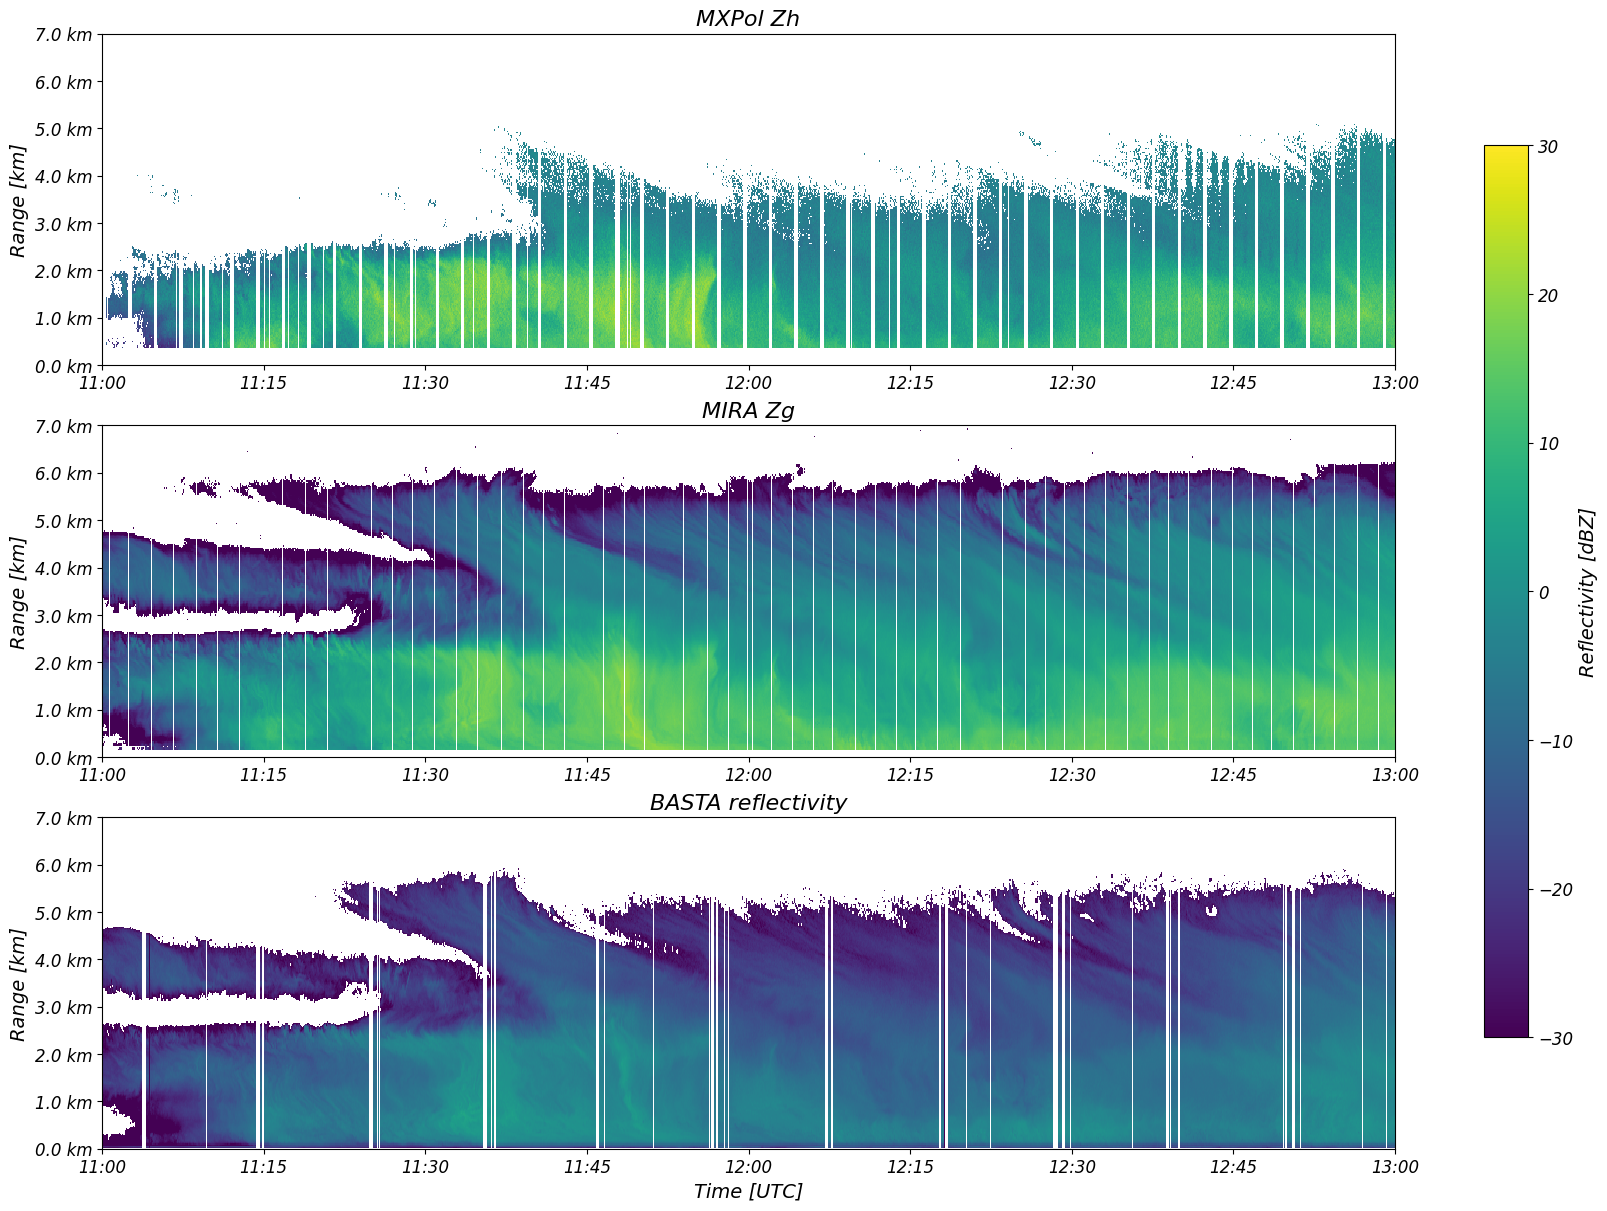

In [12]:
# plot reflectivity for all three radars
kw = dict(cmap='viridis', vmin=-30, vmax=30, shading='auto')

fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(16, 12), sharex=True, sharey=True, constrained_layout=True)

# MXPol (Zh already in dBZ)
zh = regrid_time(mxpol_nc.Zh, t0_jan, t1_jan, freq='1s').transpose('range', 'time')
pm = axs[0].pcolormesh(zh.time.values, zh.range.values, zh.values, **kw)
axs[0].set_title('MXPol Zh')

# MIRA (Zg in linear units -> dBZ)
zg = regrid_time(mira_nc.Zg, t0_jan, t1_jan, freq='5s').transpose('range', 'time')
axs[1].pcolormesh(zg.time.values, zg.range.values, 10 * np.log10(zg.values), **kw)
axs[1].set_title('MIRA Zg')

# BASTA (reflectivity already in dBZ)
z3 = regrid_time(basta_nc.reflectivity.where(basta_nc['background_mask']), t0_jan, t1_jan, freq='3s').transpose('range', 'time')
axs[2].pcolormesh(z3.time.values, z3.range.values, z3.values, **kw)
axs[2].set_title('BASTA reflectivity')

for ax in axs:
    ax.set_ylabel('Range [km]')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    ax.yaxis.set_major_formatter(FuncFormatter(meters_to_km))
    ax.tick_params(axis='x', labelbottom=True)
axs[-1].set_xlim(t0_jan, t1_jan)
axs[-1].set_ylim(0, 7e3)
axs[-1].set_xlabel('Time [UTC]')

fig.colorbar(pm, ax=axs, label='Reflectivity [dBZ]', shrink=0.8)
plt.show()

### Plot (BASTA modes)

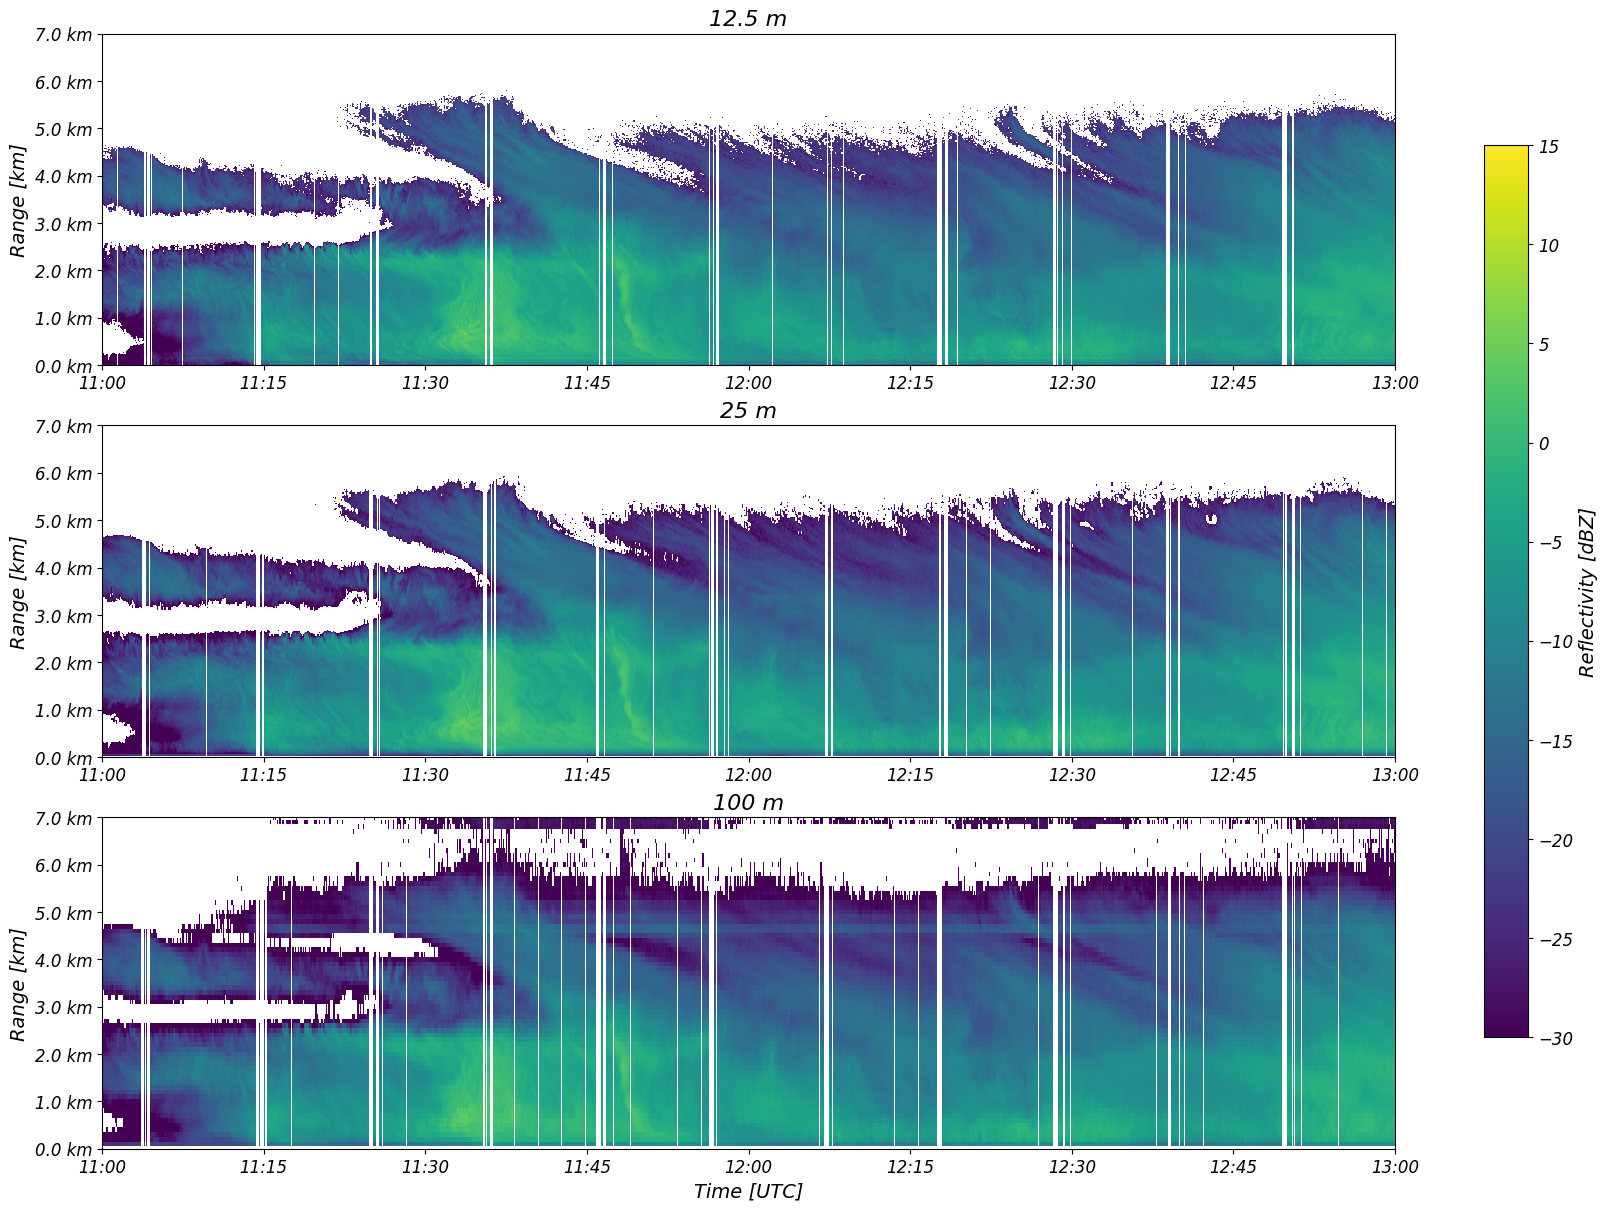

In [13]:
# background mask is used to filter for noise
# reflectivity data manually set to [-100, 100] dB since some artefact extremely low/high values still present in the L1 data
kw = dict(cmap='viridis', vmin=-30, vmax=15, shading='auto')

basta_modes = [
    ('12.5 m', basta_12m5, '3s'),
    ('25 m',   basta_25m,  '3s'),
    ('100 m',  basta_100m, '3s'),
]

fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(16, 12), sharex=True, sharey=True, constrained_layout=True)

for ax, (title, ds, freq) in zip(axs, basta_modes):
    z = ds.reflectivity
    z = z.where((z > -100) & (z < 100)).where(ds['background_mask'])
    z = regrid_time(z, t0_jan, t1_jan, freq=freq).transpose('range', 'time')
    pm = ax.pcolormesh(z.time.values, z.range.values, z.values, **kw)
    ax.set_title(title)

for ax in axs:
    ax.set_ylabel('Range [km]')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    ax.yaxis.set_major_formatter(FuncFormatter(meters_to_km))
    ax.tick_params(axis='x', labelbottom=True)
axs[-1].set_xlim(t0_jan, t1_jan)
axs[-1].set_ylim(0, 7e3)
axs[-1].set_xlabel('Time [UTC]')

fig.colorbar(pm, ax=axs, label='Reflectivity [dBZ]', shrink=0.8)
plt.show()

# 3. Scanning data - L1 files
## 2024-12-05 - data used
This section describes how to open/plot scans MXPol and MIRA from the L1 files. Note that pyart is used here to plot the scans, and in order to open MIRA .znc-files with PyArt the custom function `znc_to_pyart` and its input/helper functions as well as some mapping dictionaries are required. 

The following files were downloaded:
**MXPol**<p>
https://cloudnet.fmi.fi/instrument/b553925c-b93b-4d66-8020-bd5b5df62864/raw-files?date=2024-12-05<br>
17 files covering 11:00-12:45 UTC (vertical profiling while rotating): `XPOL-20241205-110525_Zdr.nc` to `XPOL-20241205-124533_Zdr.n`§<br>
4 scans (2 RHIs and 2 sector scans around 13:55): `XPOL-20241205-135322_RHI.nc`, `XPOL-20241205-135433_RHI.nc`, `XPOL-20241205-135804_sector.nc` and `XPOL-20241205-135220_sector.nc`

**MIRA**<p>
https://cloudnet.fmi.fi/instrument/06454930-39fe-4116-80ba-8b7b1f90c1ea/raw-files?date=2024-12-05<br>
23 files covering 11:00-14:00 UTC (vertical profiling data): `20241205_1100.znc` to `20241205_1242.znc`<br>
3 scans (2 RHIs and 1 sector scan around 13:55): `20241205_135427.rhi183.znc`, `20241205_135548.rhi93.znc` and `20241205_135124.ppi.znc`

**BASTA**<p>
https://cloudnet.fmi.fi/instrument/e9441c71-f67f-4c83-8b31-5437943371be/raw-files?date=2024-12-05<br>
1 file for the 25 m-mode covering the whole day (00:00-24:00 UTC): `BASTA_L1_25m_20241205_000002.nc`

These files can be downloaded directly from the Cloudnet Data Portal, or extracted from the `20241205.zip` file.

### Data loading

In [14]:
# radar data loading
dirname = f"{base_dir}/20241205"

mira_files_all = sorted(glob.glob(f"{dirname}/*.znc"))
mira_scans = ['20241205_135427.rhi183.znc', '20241205_135548.rhi93.znc', '20241205_135124.ppi.znc']

mxpol_files_all = sorted(glob.glob(f"{dirname}/XPOL-*.nc"))
mxpol_scans = ['XPOL-20241205-135322_RHI.nc', 'XPOL-20241205-135433_RHI.nc', 'XPOL-20241205-135804_sector.nc', 'XPOL-20241205-135220_sector.nc']

basta_file_dec = glob.glob(f"{dirname}/BASTA*.nc")[0]

In [15]:
# profiling data
mira_files_dec = [f for f in mira_files_all if os.path.basename(f) not in mira_scans]
mira_dec = xr.open_mfdataset(mira_files_dec, combine='nested', concat_dim='time', chunks='auto')
mira_dec['time'] = pd.to_datetime(mira_dec.time.values, unit='s') # convert MIRA time from seconds since epoch to datetime64

mxpol_files_dec = [f for f in mxpol_files_all if os.path.basename(f) not in mxpol_scans]
mxpol_dec = xr.open_mfdataset(mxpol_files_dec, combine='nested', concat_dim='time', chunks='auto')

basta_dec = xr.open_dataset(basta_file_dec)

In [16]:
# scans
mira_radar_rhi1 = znc_to_pyart(os.path.join(dirname, mira_scans[0])) # RHI at 183 azimuth (check mira_radar_rhi1.azimuth)
mira_radar_rhi2 = znc_to_pyart(os.path.join(dirname, mira_scans[1]))
mira_radar_sector = znc_to_pyart(os.path.join(dirname, mira_scans[2]))

mxpol_radar_rhi1 = pyart.io.read_cfradial(os.path.join(dirname, mxpol_scans[0])) # RHI at 183 azimuth (check mxpol_radar_rhi1.azimuth)
mxpol_radar_rhi2 = pyart.io.read_cfradial(os.path.join(dirname, mxpol_scans[1]))
mxpol_radar_sector = pyart.io.read_cfradial(os.path.join(dirname, mxpol_scans[-1]))

In [17]:
t0_dec, t1_dec = pd.Timestamp('2024-12-05 11:00'), pd.Timestamp('2024-12-05 12:30')

### Plot (all three radars)

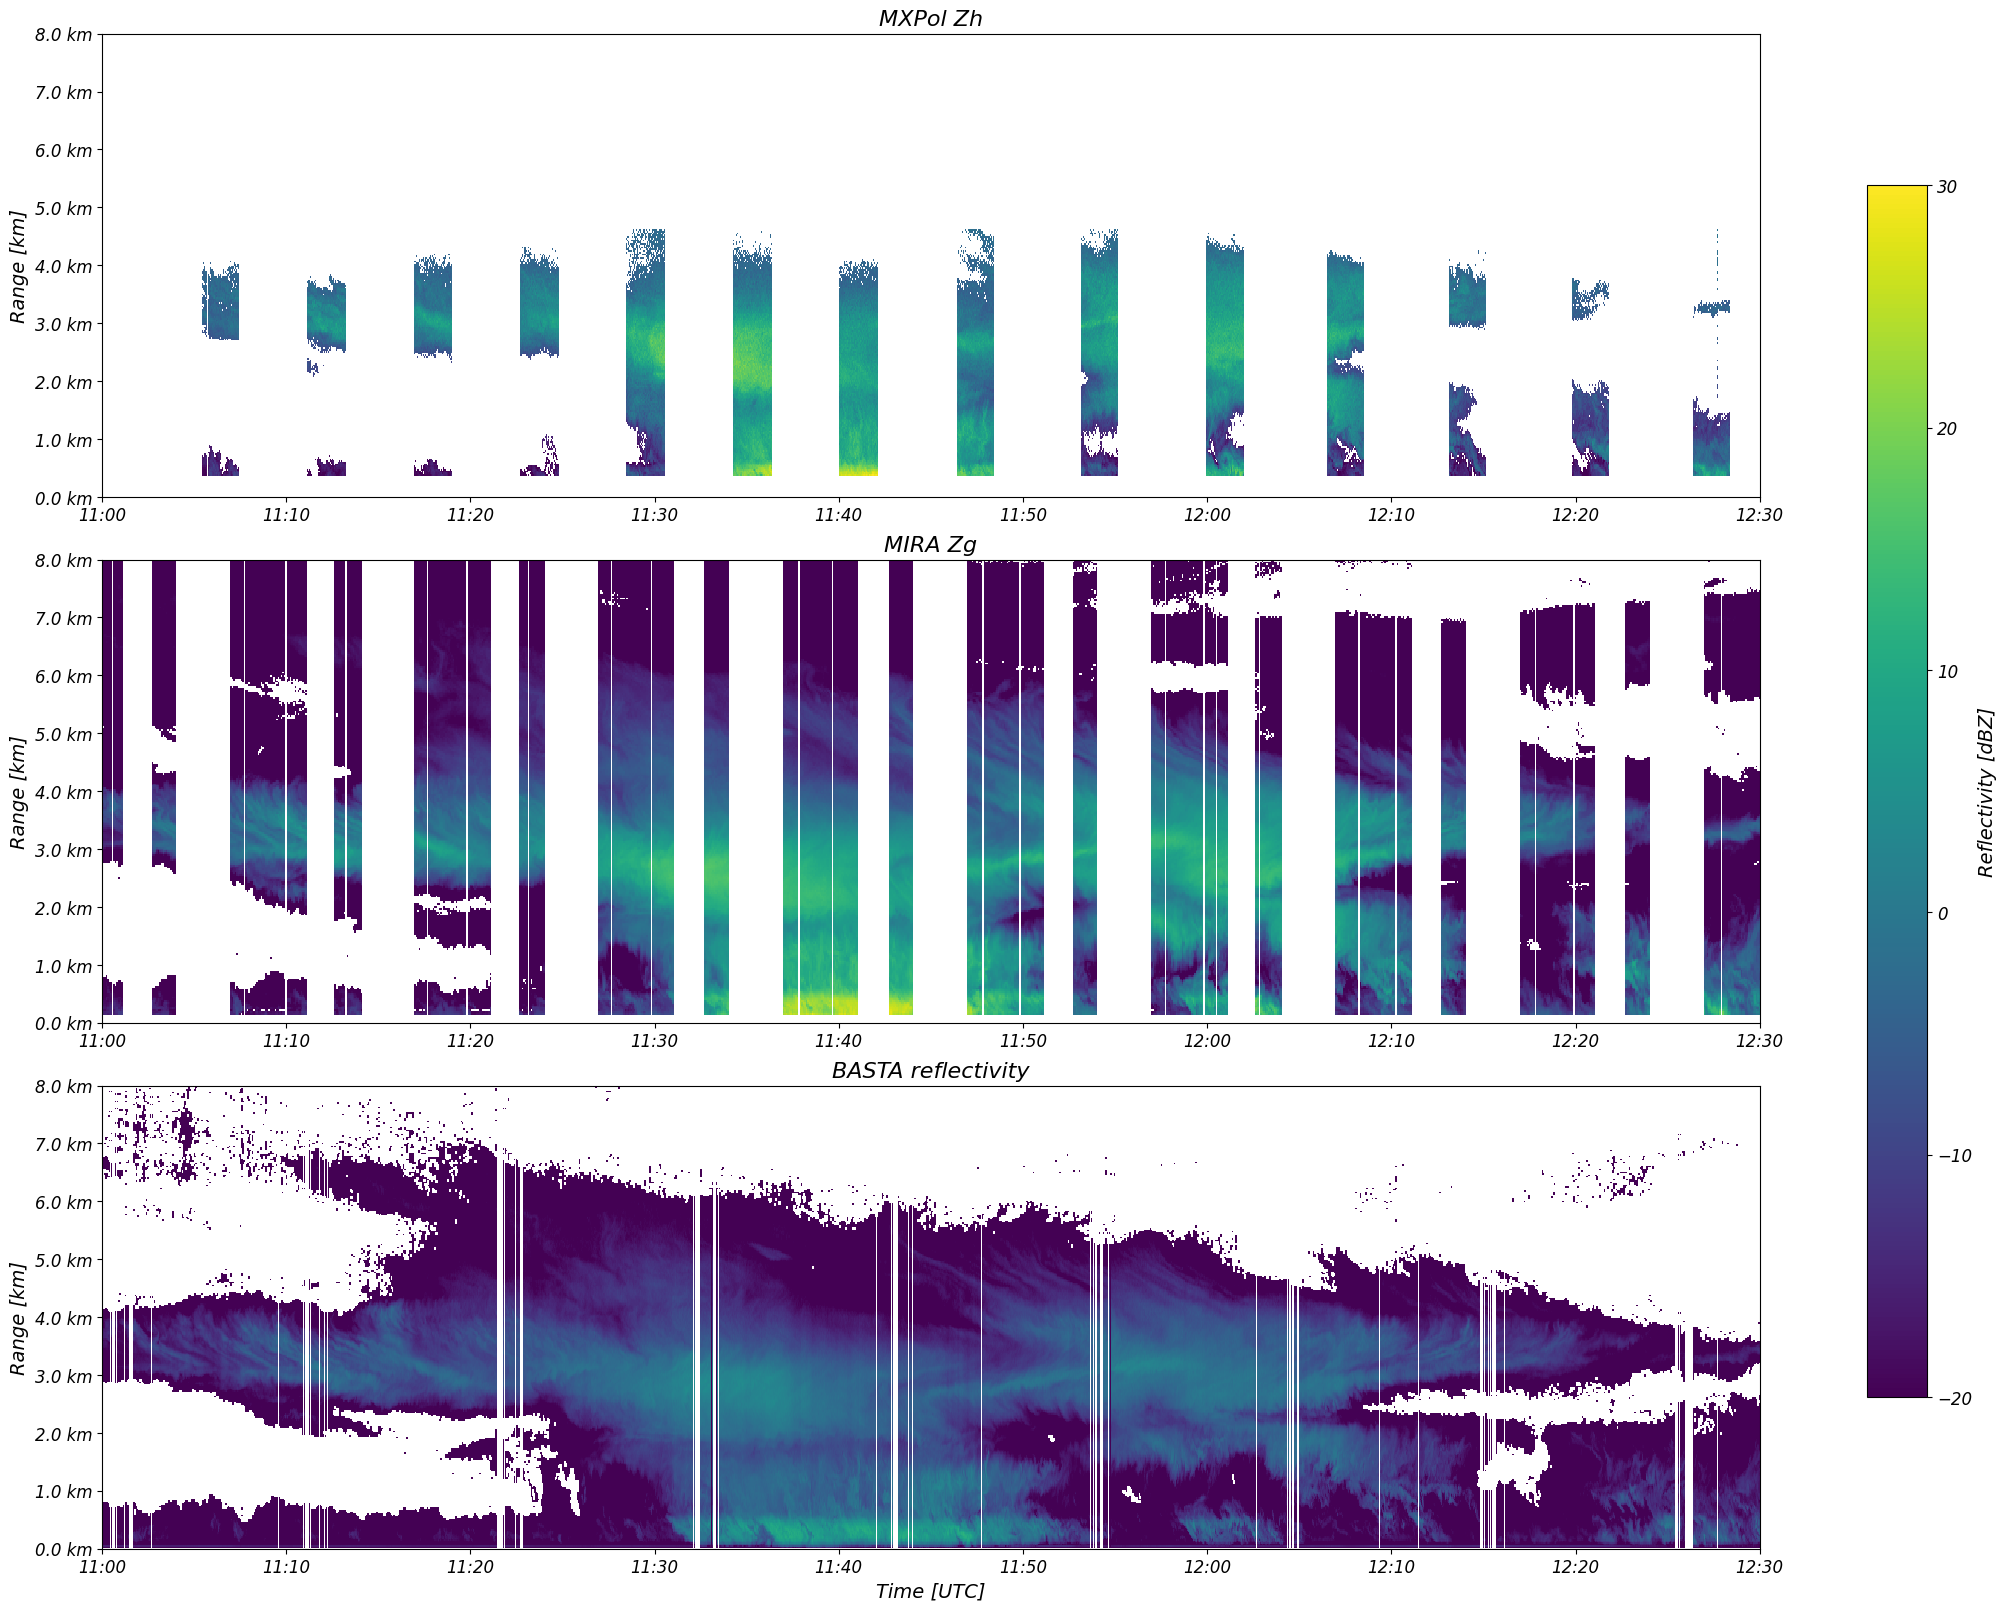

In [18]:
# plot reflectivity (vertically pointing) for all three radars
kw = dict(cmap='viridis', vmin=-20, vmax=30, shading='auto')

fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(20, 16), sharex=True, sharey=True, constrained_layout=True)

# MXPol (Zh already in dBZ)
zh = regrid_time(mxpol_dec.Zh, t0_dec, t1_dec, '1s').transpose('range', 'time')
pm = axs[0].pcolormesh(zh.time.values, zh.range.values, zh.values, **kw)
axs[0].set_title('MXPol Zh')

# MIRA (Zg in linear units -> dBZ)
zg = regrid_time(mira_dec.Zg, t0_dec, t1_dec, '5s').transpose('range', 'time')
axs[1].pcolormesh(zg.time.values, zg.range.values, 10 * np.log10(zg.values), **kw)
axs[1].set_title('MIRA Zg')

# BASTA (reflectivity already in dBZ)
z3 = regrid_time(basta_dec.reflectivity.where(basta_dec['background_mask']), t0_dec, t1_dec, freq='3s').transpose('range', 'time')
axs[2].pcolormesh(z3.time.values, z3.range.values, z3.values, **kw)
axs[2].set_title('BASTA reflectivity')

for ax in axs:
    ax.set_ylabel('Range [km]')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    ax.yaxis.set_major_formatter(FuncFormatter(meters_to_km))
    ax.tick_params(axis='x', labelbottom=True)
axs[-1].set_xlim(t0_dec, t1_dec)
axs[-1].set_ylim(0, 8e3)
axs[-1].set_xlabel('Time [UTC]')

fig.colorbar(pm, ax=axs, label='Reflectivity [dBZ]', shrink=0.8)
plt.show()

### Scan plots

In [19]:
vmin = -20
vmax = 30
cmap = 'viridis'

(0.0, 8.0)

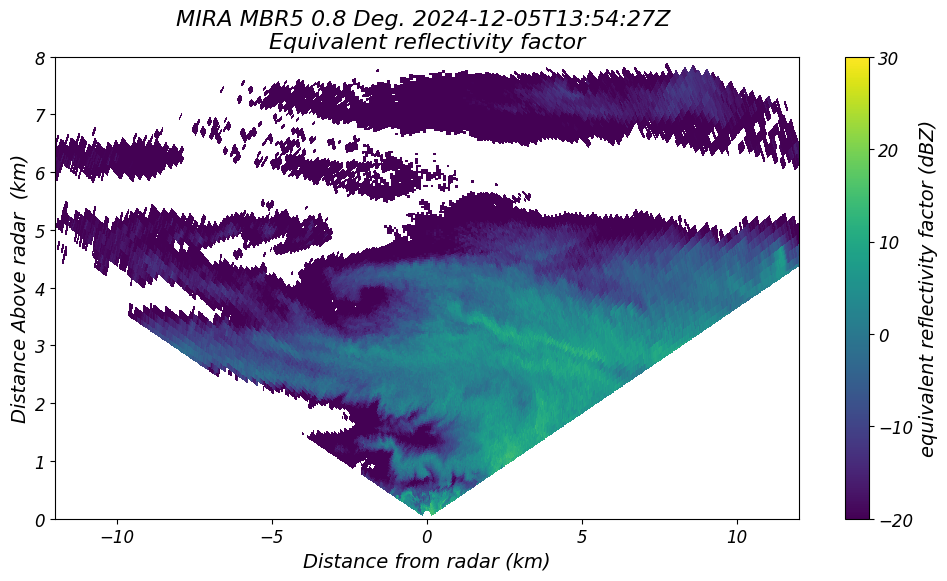

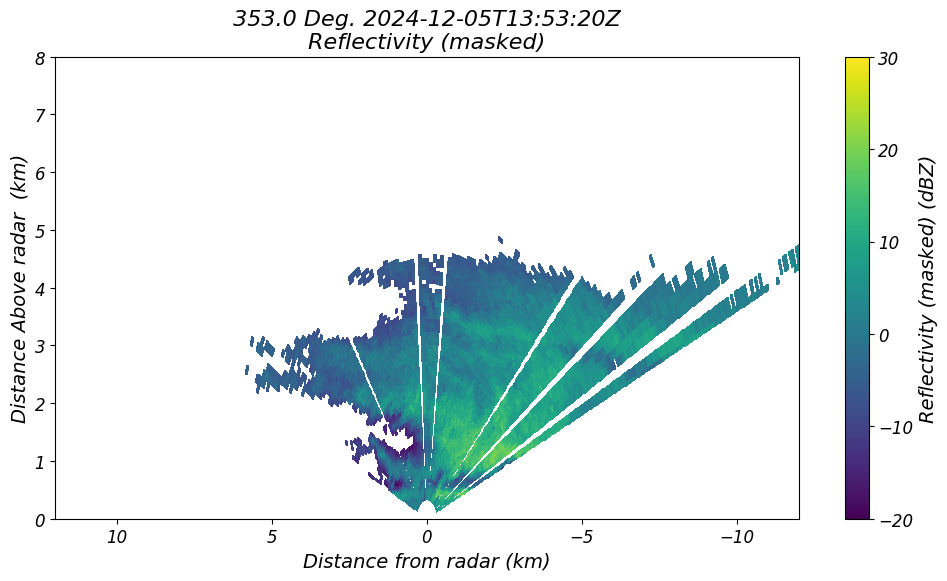

In [20]:
# MIRA & MXPol RHIs at 183 azimuth
fig, ax = plt.subplots(figsize=(12, 6))
display_mira_rhi1 = pyart.graph.RadarDisplay(mira_radar_rhi1)
display_mira_rhi1.plot_rhi('reflectivity', vmin=vmin, vmax=vmax, cmap=cmap)
ax.set_xlim([-12, 12])
ax.set_ylim([0, 8])

fig, ax = plt.subplots(figsize=(12, 6))
display_mxpol_rhi1 = pyart.graph.RadarDisplay(mxpol_radar_rhi1)
display_mxpol_rhi1.plot_rhi('Zh', vmin=vmin, vmax=vmax, cmap=cmap)
ax.set_xlim([12, -12]) # reversed x-axis to match MIRA scans (radars were scanning starting at opposite sides)
ax.set_ylim([0, 8])

(0.0, 8.0)

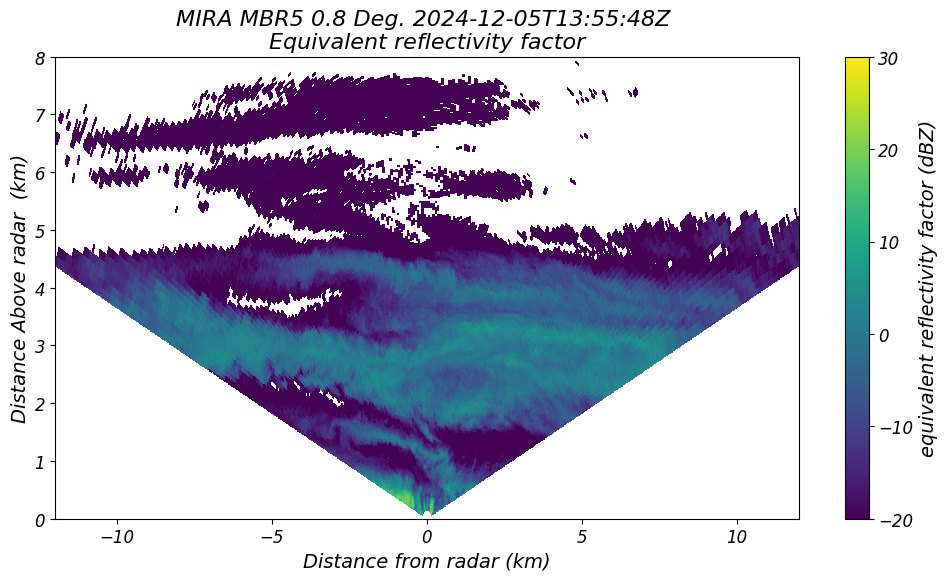

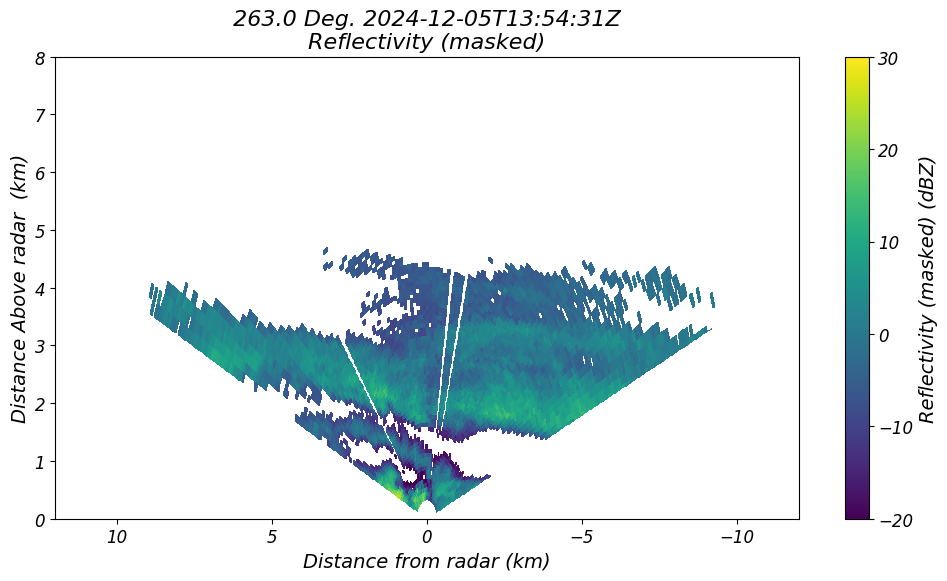

In [21]:
# MIRA and MXPol RHIs at 93 azimuth
fig, ax = plt.subplots(figsize=(12, 6))
display_mira_rhi2 = pyart.graph.RadarDisplay(mira_radar_rhi2)
display_mira_rhi2.plot_rhi('reflectivity', vmin=vmin, vmax=vmax, cmap=cmap)
ax.set_xlim([-12, 12])
ax.set_ylim([0, 8])

fig, ax = plt.subplots(figsize=(12, 6))
display_mxpol_rhi2 = pyart.graph.RadarDisplay(mxpol_radar_rhi2)
display_mxpol_rhi2.plot_rhi('Zh', vmin=vmin, vmax=vmax, cmap=cmap, ax=ax)
ax.set_xlim([12, -12])
ax.set_ylim([0, 8])

(-5.0, 15.0)

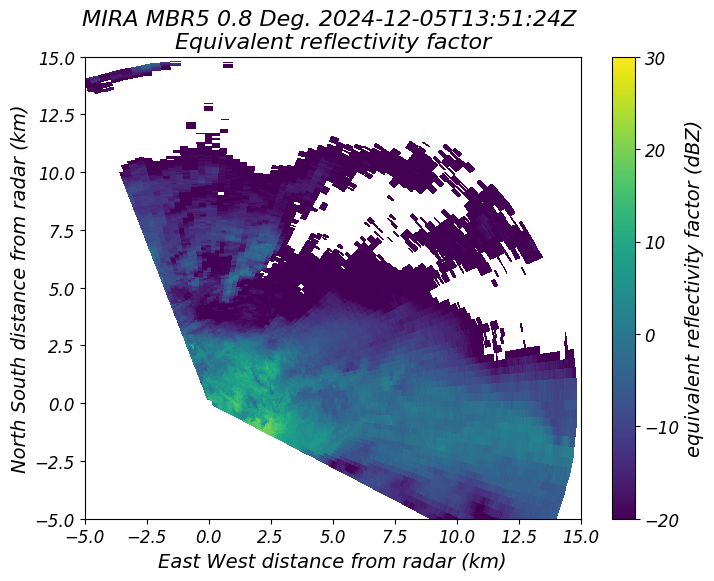

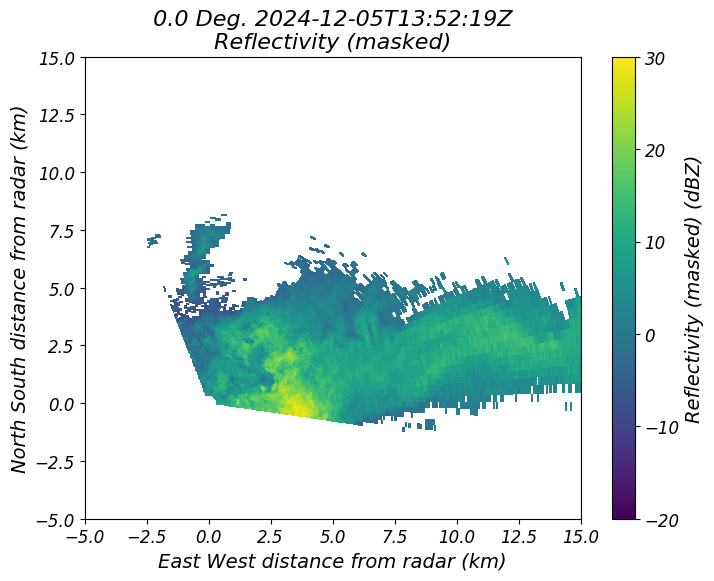

In [22]:
# MIRA and MXPol sector scans (not quite at the same time but as close as possible)
fig, ax = plt.subplots(figsize=(8, 6))
display_mira_sector = pyart.graph.RadarDisplay(mira_radar_sector)
display_mira_sector.plot_ppi('reflectivity', vmin=vmin, vmax=vmax, cmap='viridis')
ax.set_xlim([-5, 15])
ax.set_ylim([-5, 15])

fig, ax = plt.subplots(figsize=(8, 6))
display_mxpol_sector = pyart.graph.RadarDisplay(mxpol_radar_sector)
display_mxpol_sector.plot_ppi('Zh', vmin=vmin, vmax=vmax, cmap=cmap)
ax.set_xlim([-5, 15])
ax.set_ylim([-5, 15])

# 4. Zarr data

This section describes how to open/plot the .zarr files for MXPol, MIRA and BASTA on 2025-01-15 when all three instruments were operating in profiling mode.

Here, only the resampled (`30s_25m`) .zarr files are loaded to minimize download size for this tutorial, but for opening the other (unzipped) .zarr-files (`zarr_no_resampling.zip`, as well as the MXPol and MIRA .zarr-files containing spectral data `zarr_MXPolspectral.zip` and `zarr_MIRAspectral.zip`) the same code snippets can be used.

In addition to the variables in the below data sets, the following variables are available in the spectral .zarr files:<br>
**MXPol**: sZh, sZv<br>
**MIRA**: sZh, sZv, sLDR

In [23]:
dirname_zarr = '/home/clerx/cleancloud/zarr/30s_25m'

basta_zarr = xr.open_zarr(f"{dirname_zarr}/BASTA.zarr")
mira_zarr = xr.open_zarr(f"{dirname_zarr}/MIRA.zarr")
mxpol_zarr = xr.open_zarr(f"{dirname_zarr}/MXPol.zarr")

In [24]:
basta_zarr

<xarray.Dataset> Size: 14GB
Dimensions:                (time: 282241, range: 584)
Coordinates:
  * range                  (range) float64 5kB 400.0 425.0 ... 1.498e+04
  * time                   (time) datetime64[ns] 2MB 2024-10-18 ... 2025-01-24
Data variables: (12/18)
    DFR_KaW                (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    DFR_XW                 (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    background_mask        (time, range) float32 659MB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    bg_120s                (time, range) float32 659MB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    bg_30s                 (time, range) float32 659MB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    cloudtop               (time) float32 1MB dask.array<chunksize=(2880,), meta=np.ndarray>
    ...                     ...
    vel_120s               (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    vel_30s                (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    velocity               (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    z_120s                 (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    z_30s                  (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    zdi                    (time) float32 1MB dask.array<chunksize=(2880,), meta=np.ndarray>

In [25]:
mira_zarr

<xarray.Dataset> Size: 13GB
Dimensions:        (time: 282241, range: 584)
Coordinates:
  * range          (range) float64 5kB 400.0 425.0 450.0 ... 1.495e+04 1.498e+04
  * time           (time) datetime64[ns] 2MB 2024-10-18 ... 2025-01-24
Data variables: (12/13)
    DFR_KaW        (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    DFR_XKa        (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    LDR            (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    cloudtop       (time) float32 1MB dask.array<chunksize=(2880,), meta=np.ndarray>
    is_precip      (time) bool 282kB dask.array<chunksize=(2880,), meta=np.ndarray>
    numpeaks       (time, range) float32 659MB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    ...             ...
    skewness       (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    snrh           (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    snrv           (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    spectrumwidth  (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    velocity       (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    zdi            (time) float32 1MB dask.array<chunksize=(2880,), meta=np.ndarray>

In [26]:
mxpol_zarr

<xarray.Dataset> Size: 16GB
Dimensions:           (time: 282241, range: 584)
Coordinates:
  * range             (range) float64 5kB 400.0 425.0 ... 1.495e+04 1.498e+04
  * time              (time) datetime64[ns] 2MB 2024-10-18 ... 2025-01-24
Data variables: (12/14)
    DFR_XKa           (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    DFR_XW            (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    is_precip         (time) bool 282kB dask.array<chunksize=(2880,), meta=np.ndarray>
    reflectivity      (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    reflectivity_raw  (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    rhohv             (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    ...                ...
    snrv              (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    snrv_raw          (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    spectrumwidth     (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    velocity          (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>
    zdi               (time) float32 1MB dask.array<chunksize=(2880,), meta=np.ndarray>
    zdr               (time, range) float64 1GB dask.array<chunksize=(2880, 584), meta=np.ndarray>

## Converting (parts of) .zarr files to NetCDF

The `.zarr` archives can be converted to NetCDF, for example for use with tools that do not read Zarr. Because the archives cover the full campaign, it is best to select a time period (and, if needed, a subset of variables) first, as converting a full archive produces very large files.

In [ ]:
# select a time period for which to convert to .nc
t0, t1 = "2025-01-15T00:00", "2025-01-15T23:59"

for name, ds in {"BASTA": basta_zarr, "MIRA": mira_zarr, "MXPol": mxpol_zarr}.items():
    subset = ds.sel(time=slice(t0, t1))
    # optionally select variables, e.g.: subset = subset[["reflectivity", "velocity"]]

    # remove Zarr-specific storage settings (chunking, compression), which NetCDF does not accept
    subset = subset.drop_encoding()

    # write to NetCDF; float32 keeps the file small without losing precision
    encoding = {v: {"dtype": "float32", "zlib": True} for v in subset.data_vars
                if subset[v].dtype.kind == "f"}
    subset.to_netcdf(f"{name}_{t0[:10].replace('-', '')}.nc", encoding=encoding)

## 2025-01-15 
In this section, the reflectivity plot for the three radars as shown in the previous section is plotted using the data in the .zarr files instead of the L1 data.

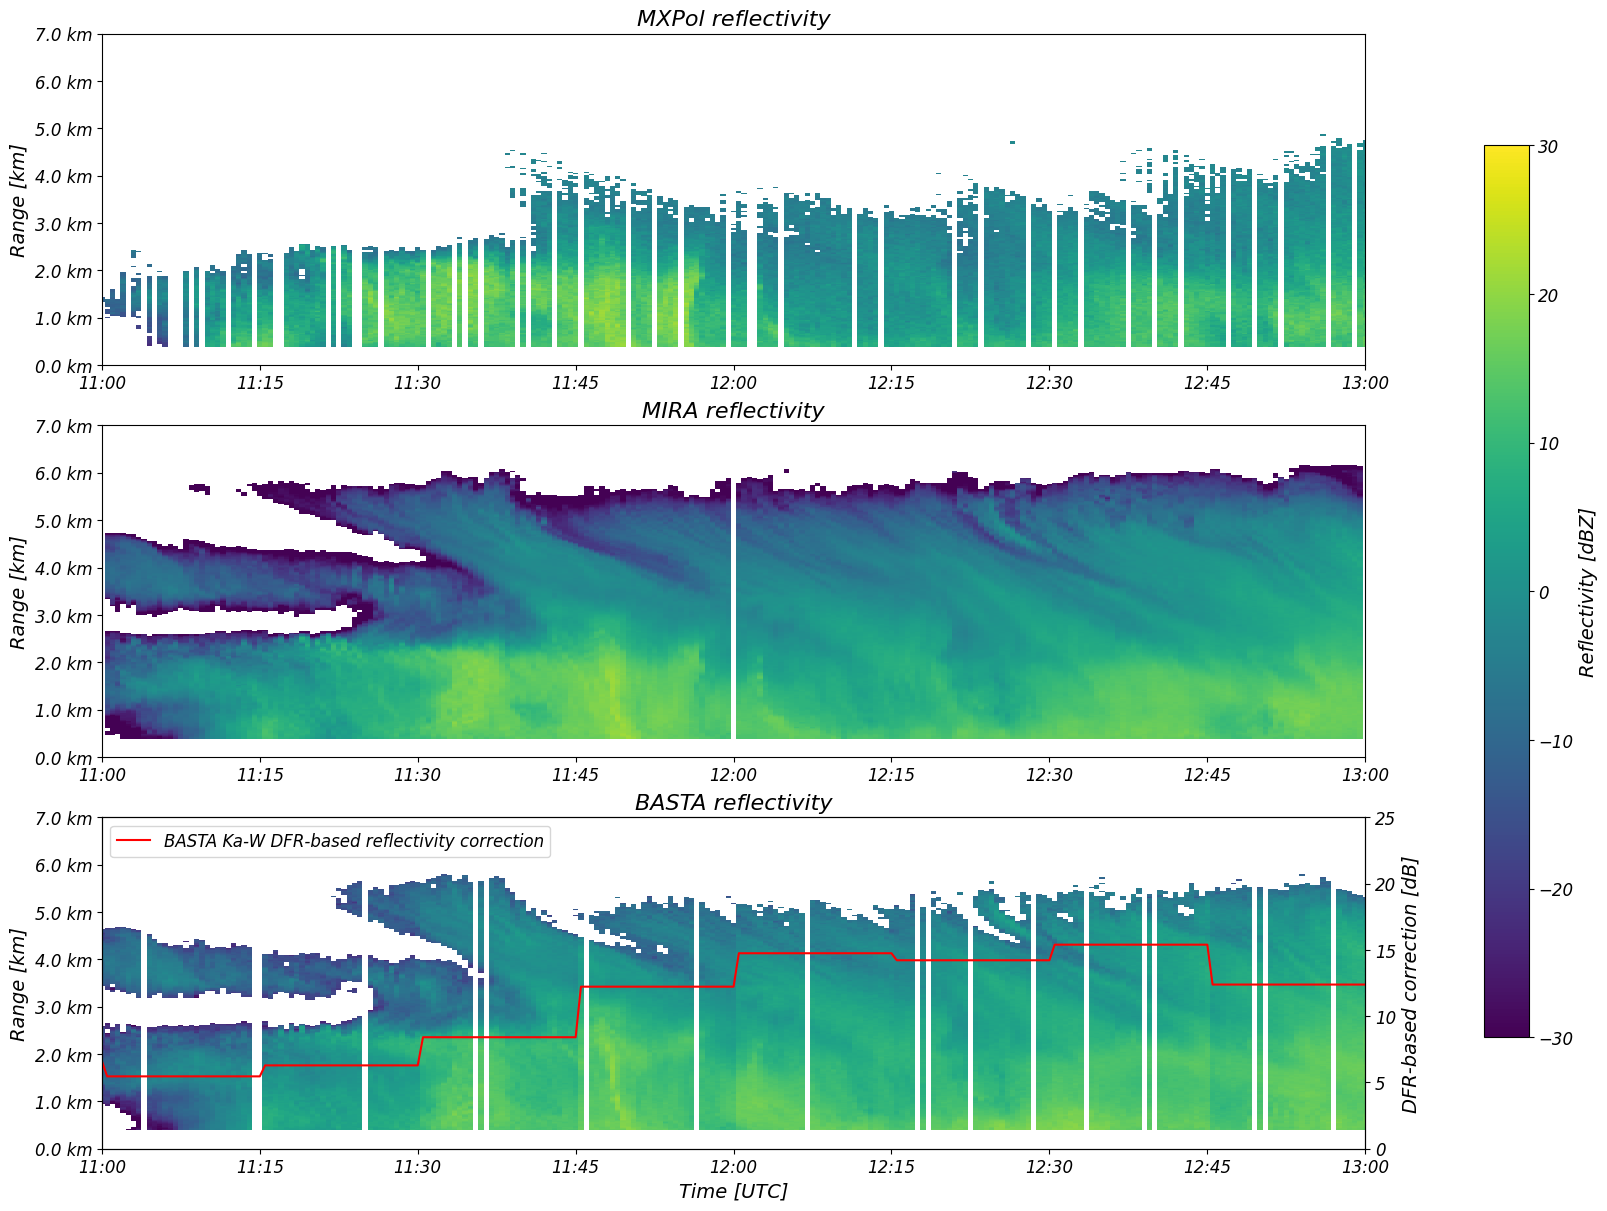

In [27]:
# plot reflectivity for all three radars
kw = dict(cmap='viridis', vmin=-30, vmax=30, shading='auto')

fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(16, 12), sharex=True, sharey=True, constrained_layout=True)

# MXPol
zh = mxpol_zarr.sel(time=slice(t0_jan, t1_jan)).reflectivity.transpose('range', 'time')
pm = axs[0].pcolormesh(zh.time.values, zh.range.values, zh.values, **kw)
axs[0].set_title('MXPol reflectivity')

# MIRA
zg = mira_zarr.sel(time=slice(t0_jan, t1_jan)).reflectivity.transpose('range', 'time')
axs[1].pcolormesh(zg.time.values, zg.range.values, zg.values, **kw)
axs[1].set_title('MIRA reflectivity')

# BASTA
z3 = basta_zarr.sel(time=slice(t0_jan, t1_jan)).reflectivity.transpose('range', 'time')
axs[2].pcolormesh(z3.time.values, z3.range.values, z3.values, **kw)
axs[2].set_title('BASTA reflectivity')

ax2 = axs[2].twinx()
ax2.plot(z3.time.values, basta_zarr.sel(time=slice(t0_jan, t1_jan)).cloudtopDFRs, 'r', label='BASTA Ka-W DFR-based reflectivity correction')
ax2.set_ylim(0, 25)
ax2.set_ylabel('DFR-based correction [dB]')
ax2.legend(loc='upper left')

for ax in axs:
    ax.set_ylabel('Range [km]')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    ax.yaxis.set_major_formatter(FuncFormatter(meters_to_km))
    ax.tick_params(axis='x', labelbottom=True)
axs[-1].set_xlim(t0_jan, t1_jan)
axs[-1].set_ylim(0, 7e3)
axs[-1].set_xlabel('Time [UTC]')

fig.colorbar(pm, ax=axs, label='Reflectivity [dBZ]', shrink=0.8)
plt.show()

## 2024-12-05
Like above, but then for another date.

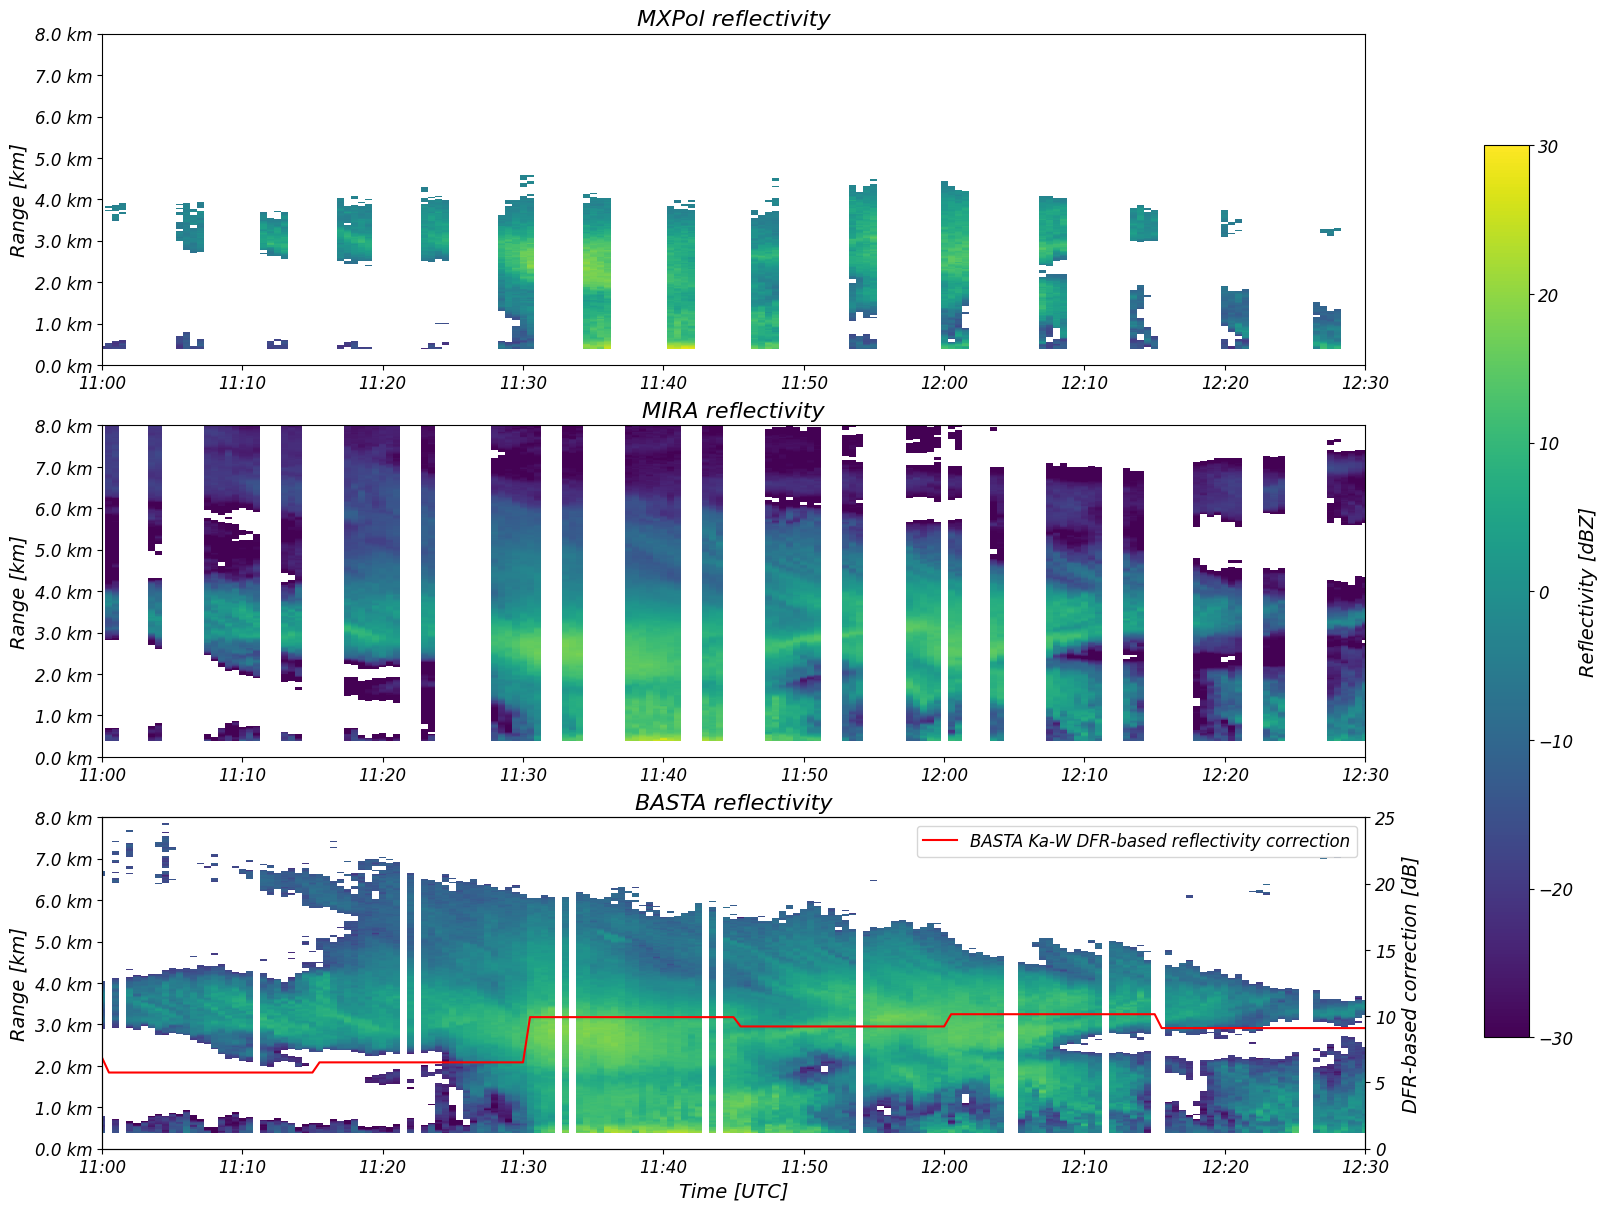

In [28]:
# plot reflectivity for all three radars
kw = dict(cmap='viridis', vmin=-30, vmax=30, shading='auto')

fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(16, 12), sharex=True, sharey=True, constrained_layout=True)

# MXPol
zh = mxpol_zarr.sel(time=slice(t0_dec, t1_dec)).reflectivity.transpose('range', 'time')
pm = axs[0].pcolormesh(zh.time.values, zh.range.values, zh.values, **kw)
axs[0].set_title('MXPol reflectivity')

# MIRA
zg = mira_zarr.sel(time=slice(t0_dec, t1_dec)).reflectivity.transpose('range', 'time')
axs[1].pcolormesh(zg.time.values, zg.range.values, zg.values, **kw)
axs[1].set_title('MIRA reflectivity')

# BASTA
z3 = basta_zarr.sel(time=slice(t0_dec, t1_dec)).reflectivity.transpose('range', 'time')
axs[2].pcolormesh(z3.time.values, z3.range.values, z3.values, **kw)
axs[2].set_title('BASTA reflectivity')
ax2 = axs[2].twinx()
ax2.plot(z3.time.values, basta_zarr.sel(time=slice(t0_dec, t1_dec)).cloudtopDFRs, 'r', label='BASTA Ka-W DFR-based reflectivity correction')
ax2.set_ylim(0, 25)
ax2.set_ylabel('DFR-based correction [dB]')
ax2.legend(loc='upper right')

for ax in axs:
    ax.set_ylabel('Range [km]')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    ax.yaxis.set_major_formatter(FuncFormatter(meters_to_km))
    ax.tick_params(axis='x', labelbottom=True)
axs[-1].set_xlim(t0_dec, t1_dec)
axs[-1].set_ylim(0, 8e3)
axs[-1].set_xlabel('Time [UTC]')

fig.colorbar(pm, ax=axs, label='Reflectivity [dBZ]', shrink=0.8)
plt.show()